<a href="https://colab.research.google.com/github/Mutaqie/Latihan-Machine-Learning/blob/main/BAB%202/Latihan_Praktikum_Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 2.12 Implementasi Python — Learning Curve & Bias-Variance

## Praktikum 2.1 Persiapan Library

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.tree import DecisionTreeClassifier

## Praktikum 2.2 Import Dataset (Telco Customer Churn)

In [3]:
import os
import pandas as pd

FILE = "WA_Fn-UseC_-Telco-Customer-Churn.csv"

# Di Google Colab: upload file CSV jika belum ada
if not os.path.exists(FILE):
    try:
        from google.colab import files
        files.upload()          # pilih file WA_Fn-UseC_-Telco-Customer-Churn.csv
    except ImportError:
        raise FileNotFoundError(f"Letakkan {FILE} di folder yang sama dengan notebook ini.")

df = pd.read_csv(FILE)
print("Ukuran data:", df.shape)
df.head()

Ukuran data: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.info()
print()
print("Distribusi kelas (Churn):")
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True).round(3))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## Praktikum 2.3 Preprocessing: Cleaning, Encoding & Stratified Split

In [9]:
import numpy as np
from sklearn.model_selection import train_test_split

# 1) Hapus kolom ID jika masih ada (tidak informatif)
df = df.drop(columns="customerID", errors="ignore")

# 2) TotalCharges bertipe teks; ubah ke numerik (nilai kosong -> NaN)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing TotalCharges:", df["TotalCharges"].isna().sum(),
      "| tenure pada baris tsb:", df.loc[df["TotalCharges"].isna(), "tenure"].unique())
df["TotalCharges"] = df["TotalCharges"].fillna(0)   # pelanggan baru (tenure=0) belum ditagih

# 3) Target biner & One-Hot Encoding fitur kategorik
y = (df["Churn"] == "Yes").astype(int).values
X = pd.get_dummies(df.drop(columns="Churn", errors="ignore"), drop_first=True).astype(float)
print("Jumlah fitur setelah encoding:", X.shape[1])

# 4) Stratified split 80:20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Proporsi kelas train:", np.bincount(y_train) / len(y_train))
print("Proporsi kelas test :", np.bincount(y_test) / len(y_test))
baseline = np.bincount(y_train).max() / len(y_train)
print("Baseline (selalu tebak 'No'):", round(baseline, 3))

Missing TotalCharges: 0 | tenure pada baris tsb: []
Jumlah fitur setelah encoding: 30
Proporsi kelas train: [0.73464679 0.26535321]
Proporsi kelas test : [0.73456352 0.26543648]
Baseline (selalu tebak 'No'): 0.735


## Praktikum 2.4 Training Model & Learning Curve

In [11]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import learning_curve
import numpy as np

model = DecisionTreeClassifier(max_depth=4, random_state=42)

train_sizes, train_scores, val_scores = learning_curve(
    model, X_train, y_train,
    cv=5, train_sizes=np.linspace(0.1, 1.0, 8),
    scoring="accuracy")
train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)

## Praktikum 2.5 Evaluasi

In [12]:
print("Skor train pada ukuran data terbesar :", round(train_mean[-1], 3))
print("Skor validasi pada ukuran data terbesar:", round(val_mean[-1], 3))
print("Gap (indikasi overfitting jika besar)  :", round(train_mean[-1] - val_mean[-1], 3))

Skor train pada ukuran data terbesar : 0.797
Skor validasi pada ukuran data terbesar: 0.782
Gap (indikasi overfitting jika besar)  : 0.015


## Praktikum 2.6 Visualisasi

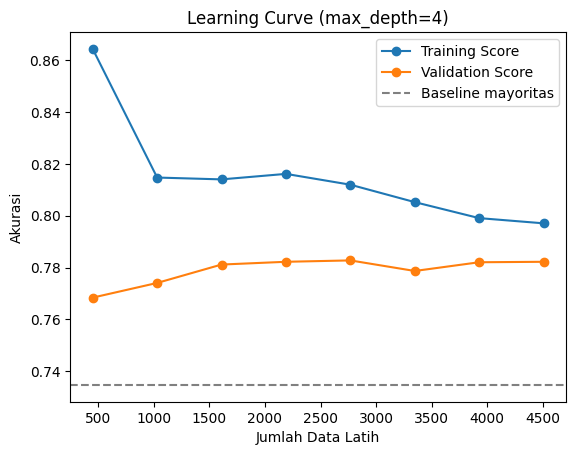

In [14]:
import matplotlib.pyplot as plt

plt.plot(train_sizes, train_mean, 'o-', label='Training Score')
plt.plot(train_sizes, val_mean, 'o-', label='Validation Score')
plt.axhline(baseline, ls='--', color='gray', label='Baseline mayoritas')
plt.xlabel('Jumlah Data Latih')
plt.ylabel('Akurasi')
plt.title('Learning Curve (max_depth=4)')
plt.legend()
plt.show()

### 2.12.1 Interpretasi

- Skor train ≈ **0,797**, skor validasi ≈ **0,782**, gap ≈ **0,015**.
- Gap sangat kecil dan validasi berada di atas baseline mayoritas (0,735), sehingga model `max_depth=4` memiliki **keseimbangan bias-variance yang baik** dan siap dievaluasi lebih lanjut pada test set.
- Karena data tidak seimbang (±26,5% churn), akurasi saja belum cukup; evaluasi lanjutan sebaiknya memakai recall/F1 kelas churn (lihat fase Evaluation pada CRISP-DM).

---
## 2.13 Latihan Praktikum

### Praktikum 2.7 (Latihan 2): Learning curve untuk `max_depth` berbeda

In [15]:
# Bandingkan learning curve untuk max_depth berbeda
for depth in [1, 4, None]:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    train_sizes, train_scores, val_scores = learning_curve(
        model, X_train, y_train,
        cv=5, train_sizes=np.linspace(0.1, 1.0, 6))
    print(f"max_depth={depth}: train={train_scores.mean():.3f}, "
          f"val={val_scores.mean():.3f}")
# Tuliskan diagnosis (underfitting/overfitting/seimbang) untuk setiap nilai max_depth.

max_depth=1: train=0.744, val=0.727
max_depth=4: train=0.818, val=0.781
max_depth=None: train=0.999, val=0.728


### Tambahan: grafik & gap pada ukuran data terbesar

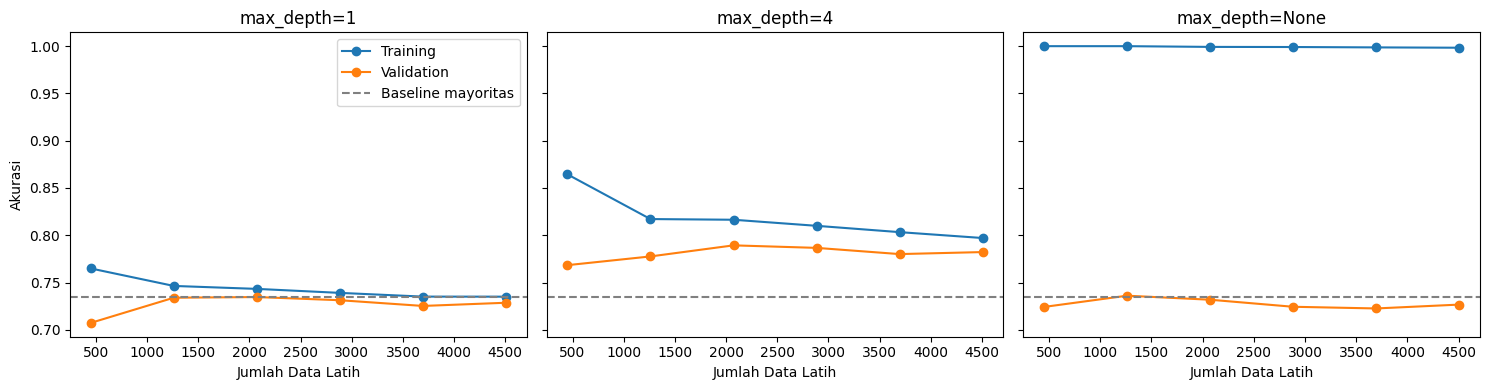

,max_depth,train (data terbesar),val (data terbesar),gap
0,1.0,0.735,0.729,0.006
1,4.0,0.797,0.782,0.015
2,NaN,0.998,0.727,0.272


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
rows = []
for ax, depth in zip(axes, [1, 4, None]):
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    ts, trs, vs = learning_curve(model, X_train, y_train,
                                 cv=5, train_sizes=np.linspace(0.1, 1.0, 6))
    tr, va = trs.mean(axis=1), vs.mean(axis=1)
    ax.plot(ts, tr, 'o-', label='Training')
    ax.plot(ts, va, 'o-', label='Validation')
    ax.axhline(baseline, ls='--', color='gray', label='Baseline mayoritas')
    ax.set_title(f'max_depth={depth}')
    ax.set_xlabel('Jumlah Data Latih')
    rows.append({'max_depth': depth, 'train (data terbesar)': round(tr[-1], 3),
                 'val (data terbesar)': round(va[-1], 3), 'gap': round(tr[-1]-va[-1], 3)})
axes[0].set_ylabel('Akurasi'); axes[0].legend()
plt.tight_layout(); plt.show()
pd.DataFrame(rows)

#### Diagnosis

| max_depth | Train / Val (rata-rata) | Train / Val (data terbesar) | Gap | Diagnosis |
|---|---|---|---|---|
| 1 | 0,744 / 0,727 | 0,735 / 0,729 | 0,006 | **Underfitting (high bias)**: skor validasi (≈ 0,73) tidak lebih baik dari baseline mayoritas (0,735). Model terlalu sederhana; gap kecil bukan tanda model bagus. |
| 4 | 0,818 / 0,781 | 0,797 / 0,782 | 0,015 | **Seimbang (good fit)**: skor tertinggi pada validasi, di atas baseline, gap kecil, kurva saling mendekat. |
| None | 0,999 / 0,728 | 0,998 / 0,727 | 0,272 | **Overfitting (high variance)**: train hampir sempurna (menghafal data latih), tetapi validasi turun ke level baseline; gap sangat besar. |

**Kesimpulan:** `max_depth=4` terbaik. Pohon terlalu dangkal gagal menangkap pola churn (bias tinggi), sedangkan pohon tanpa batas kedalaman menghafal noise (variance tinggi).

### Praktikum 1 (Latihan 1): Pemetaan proyek ke CRISP-DM

**Studi kasus:** Prediksi *churn* pelanggan telekomunikasi — dataset Telco Customer Churn (7.043 pelanggan, 21 kolom).

| Fase CRISP-DM | Aktivitas konkret (sesuai yang dikerjakan di notebook ini) |
|---|---|
| **1. Business Understanding** | Tujuan bisnis: menekan pelanggan yang berhenti berlangganan, karena mempertahankan pelanggan lebih murah daripada mencari pelanggan baru. Tujuan ML: klasifikasi biner `Churn` (Yes/No) untuk menghasilkan daftar pelanggan berisiko bagi tim retensi. Kriteria sukses: recall dan F1 kelas churn (bukan hanya akurasi), karena kelas churn hanya ±26,5%. |
| **2. Data Understanding** | Memuat CSV (7.043 baris × 21 kolom) dan memeriksa `df.info()`. Menemukan `TotalCharges` bertipe teks dengan 11 nilai kosong (semuanya pelanggan `tenure = 0`). Distribusi target tidak seimbang: No 5.174 (73,5%) vs Yes 1.869 (26,5%). Eksplorasi churn per `Contract`: month-to-month ≈ 42,7%, one year ≈ 11,3%, two year ≈ 2,8%. |
| **3. Data Preparation** | Menghapus `customerID`; mengubah `TotalCharges` ke numerik dan mengisi nilai kosong dengan 0; One-Hot Encoding fitur kategorik (21 kolom menjadi 30 fitur); memisahkan target; *stratified train-test split* 80:20 (proporsi churn terjaga ±26,5% di train dan test). |
| **4. Modeling** | Melatih `DecisionTreeClassifier`; membuat learning curve dengan 5-fold cross-validation; membandingkan `max_depth` 1, 4, dan None untuk mendiagnosis underfitting/overfitting; memilih `max_depth=4`. Pengembangan lanjut: Logistic Regression, Random Forest, Gradient Boosting, dan *hyperparameter tuning*. |
| **5. Evaluation** | Membandingkan skor train vs validasi dan baseline mayoritas (0,735) untuk memastikan model benar-benar belajar. Tahap berikutnya: evaluasi pada test set dengan confusion matrix, precision, recall, F1, ROC-AUC; analisis feature importance (mis. kontrak bulanan dan tenure pendek berisiko tinggi); memutuskan apakah model memenuhi tujuan bisnis. |
| **6. Deployment** | Menyimpan model terlatih (`joblib`); membuat layanan prediksi (Flask/FastAPI/Streamlit) yang memberi skor risiko churn per pelanggan; mengintegrasikan ke CRM tim retensi; memantau performa dan *data drift*; menjadwalkan *retraining* berkala serta dokumentasi.